In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 16장 RNN과 어텐션을 사용한 자연어 처리

## 16.1 Char-RNN으로 셰익스피어 문체 생성하기

### 16.1.1 훈련 데이터셋 만들기

In [2]:
shakespeare_url = 'https://homl.info/shakespeare'
filepath = tf.keras.utils.get_file('shakespeare.txt', shakespeare_url)
with open(filepath) as f:
    shakespeare_text = f.read()

In [3]:
print(shakespeare_text[:80])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.


In [4]:
text_vec_layer = tf.keras.layers.TextVectorization(split='character',
                                                   standardize='lower')
text_vec_layer.adapt([shakespeare_text])
encoded = text_vec_layer([shakespeare_text])[0] - 2
encoded

<tf.Tensor: shape=(1115394,), dtype=int64, numpy=array([19,  5,  8, ..., 20, 26, 10], shape=(1115394,))>

In [5]:
n_tokens = text_vec_layer.vocabulary_size() - 2
n_tokens

39

In [6]:
dataset_size = len(encoded)
dataset_size

1115394

In [7]:
def to_dataset(sequence, length, shuffle=False, seed=None, batch_size=32):
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=1, drop_remainder=True)
    ds = ds.flat_map(lambda window_ds: window_ds.batch(length + 1))
    if shuffle:
        ds = ds.shuffle(buffer_size=100_000, seed=seed)
    ds = ds.batch(batch_size)
    return ds.map(lambda window: (window[:, :-1], window[:, 1:])).prefetch(1)

In [8]:
tf.random.set_seed(42)

length = 100
train_set = to_dataset(encoded[:1_000_000], length=length, shuffle=True, seed=42)
valid_set = to_dataset(encoded[1_000_000:1_060_000], length=length)
test_set = to_dataset(encoded[1_060_000:], length=length)

### 16.1.2 Char-RNN 모델 만들고 훈련하기

In [9]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None,)),
    tf.keras.layers.Embedding(input_dim=n_tokens, output_dim=16),
    tf.keras.layers.GRU(128, return_sequences=True),
    tf.keras.layers.Dense(n_tokens, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
model_ckpt = tf.keras.callbacks.ModelCheckpoint(
    'my_shakespeare_model.keras', monitor='val_accuracy', save_best_only=True)
history = model.fit(train_set, epochs=10, validation_data=valid_set, callbacks=[model_ckpt])

Epoch 1/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1491s 47ms/step - accuracy: 0.5770 - loss: 1.3791 - val_accuracy: 0.5351 - val_loss: 1.5988
Epoch 2/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1424s 45ms/step - accuracy: 0.5973 - loss: 1.2920 - val_accuracy: 0.5429 - val_loss: 1.5739
Epoch 3/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1616s 51ms/step - accuracy: 0.6015 - loss: 1.2735 - val_accuracy: 0.5432 - val_loss: 1.5656
Epoch 4/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1421s 45ms/step - accuracy: 0.6040 - loss: 1.2630 - val_accuracy: 0.5462 - val_loss: 1.5624
Epoch 5/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1683s 54ms/step - accuracy: 0.6052 - loss: 1.2571 - val_accuracy: 0.5463 - val_loss: 1.5625
Epoch 6/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1425s 45ms/step - accuracy: 0.6062 - loss: 1.2525 - val_accuracy: 0.5471 - val_loss: 1.5622
Epoch 7/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1574s 50ms/step - accuracy: 0.6069 - loss: 1.2494 - val_accuracy: 0.5477 - val_loss: 1.5625
Epoch 8/10
31247/31247 ━━━━━━━━━━━━━━━━━━━━ 1509

In [10]:
shakespeare_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(), dtype=tf.string),
    text_vec_layer,
    tf.keras.layers.Lambda(lambda X: X - 2),
    model
])

In [11]:
sample_text = 'To be or not to b'

y_proba = shakespeare_model.predict(np.array([sample_text], dtype='object'))[0, -1]
y_pred = tf.argmax(y_proba)
text_vec_layer.get_vocabulary()[y_pred + 2]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


np.str_('e')

### 16.1.3 가짜 셰익스피어 텍스트 생성하기

In [12]:
log_probas = tf.math.log([[0.5, 0.4, 0.1]])
tf.random.categorical(log_probas, num_samples=8, seed=42)

<tf.Tensor: shape=(1, 8), dtype=int64, numpy=array([[0, 1, 1, 2, 1, 1, 0, 2]])>

In [13]:
def next_char(text, temperature=1):
    y_proba = shakespeare_model.predict(np.array([text], dtype='object'), verbose=0)[0, -1:]
    rescaled_logits = tf.math.log(y_proba) / temperature
    char_id = tf.random.categorical(rescaled_logits, num_samples=1)[0, 0]
    return text_vec_layer.get_vocabulary()[char_id + 2]

In [14]:
def extend_text(text, n_chars=50, temperature=1):
    for _ in range(n_chars):
        text += next_char(text, temperature)
    return text

In [15]:
tf.random.set_seed(42)
sample_text = 'To be or not to be'

In [16]:
print(extend_text(sample_text, temperature=0.01))

To be or not to be a word.

provost:
i will not be a word than the s


In [17]:
print(extend_text(sample_text, temperature=1))

To be or not to be gilpents
upon power: thou art been
be a costly wa


In [18]:
print(extend_text(sample_text, temperature=100))

To be or not to bef ,mt'&tzfpady-$
wh-nse?pws3ert--vgerdjw!c-y-ewznj


### 16.1.4 상태가 있는 RNN

In [19]:
def to_dataset_for_stateful_rnn(sequence, length):
    def set_shape(window):
        X = window[:, :-1]
        Y = window[:, 1:]
        X.set_shape([1, length])
        Y.set_shape([1, length])
        return X, Y
    
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=length, drop_remainder=True)
    ds = ds.flat_map(lambda window: window.batch(length + 1)).batch(1)
    return ds.map(set_shape).prefetch(1)

stateful_train_set = to_dataset_for_stateful_rnn(encoded[:1_000_000], length)
stateful_valid_set = to_dataset_for_stateful_rnn(encoded[1_000_000:1_060_000], length)
stateful_test_set = to_dataset_for_stateful_rnn(encoded[1_060_000:], length)

In [20]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(batch_shape=(1, None)),
    tf.keras.layers.Embedding(input_dim=n_tokens, output_dim=16),
    tf.keras.layers.GRU(128, return_sequences=True, stateful=True),
    tf.keras.layers.Dense(n_tokens, activation='softmax')
])

In [21]:
class ResetStatesCallback(tf.keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs):
        self.model.layers[1].reset_states()

In [22]:
model_ckpt = tf.keras.callbacks.ModelCheckpoint(
    'my_stateful_shakespeare_model.keras', monitor='val_accuracy', mode='max', save_best_only=True)

model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(stateful_train_set, epochs=10, validation_data=stateful_valid_set,
                    callbacks=[ResetStatesCallback(), model_ckpt])

Epoch 1/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 176s 17ms/step - accuracy: 0.4503 - loss: 1.8671 - val_accuracy: 0.4931 - val_loss: 1.6954
Epoch 2/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 173s 17ms/step - accuracy: 0.5294 - loss: 1.5583 - val_accuracy: 0.5174 - val_loss: 1.6138
Epoch 3/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 173s 17ms/step - accuracy: 0.5492 - loss: 1.4816 - val_accuracy: 0.5304 - val_loss: 1.5804
Epoch 4/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 174s 17ms/step - accuracy: 0.5586 - loss: 1.4444 - val_accuracy: 0.5342 - val_loss: 1.5653
Epoch 5/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 175s 17ms/step - accuracy: 0.5648 - loss: 1.4217 - val_accuracy: 0.5372 - val_loss: 1.5513
Epoch 6/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 174s 17ms/step - accuracy: 0.5687 - loss: 1.4065 - val_accuracy: 0.5388 - val_loss: 1.5457
Epoch 7/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 175s 17ms/step - accuracy: 0.5713 - loss: 1.3957 - val_accuracy: 0.5400 - val_loss: 1.5403
Epoch 8/10
9999/9999 ━━━━━━━━━━━━━━━━━━━━ 175s 18ms/step - accuracy: 

## 16.2 감정 분석

In [23]:
import tensorflow_datasets as tfds

raw_train_set, raw_valid_set, raw_test_set = tfds.load(
    name='imdb_reviews',
    split=['train[:90%]', 'train[90%:]', 'test'],
    as_supervised=True
)

train_set = raw_train_set.shuffle(5000, seed=42).batch(32).prefetch(1)
valid_set = raw_valid_set.batch(32).prefetch(1)
test_set = raw_test_set.batch(32).prefetch(1)

In [24]:
for review, label in raw_train_set.take(4):
    print(review.numpy().decode('utf-8'))
    print('label:', label.numpy())
    print()

This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting could not redeem this movie's ridiculous storyline. This movie is an early nineties US propaganda piece. The most pathetic scenes were those when the Columbian rebels were making their cases for revolutions. Maria Conchita Alonso appeared phony, and her pseudo-love affair with Walken was nothing but a pathetic emotional plug in a movie that was devoid of any real meaning. I am disappointed that there are movies like this, ruining actor's like Christopher Walken's good name. I could barely sit through it.
label: 0

I have been known to fall asleep during films, but this is usually due to a combination of things including, really tired, being warm and comfortable on the sette and having just eaten a lot. However on this occasion I fell asleep because the film was rubbish. The plot developmen

In [25]:
vocab_size = 1000
text_vec_layer = tf.keras.layers.TextVectorization(max_tokens=vocab_size)
text_vec_layer.adapt(train_set.map(lambda reviews, labels: reviews))

In [26]:
tf.random.set_seed(42)

embed_size = 128
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(), dtype='string'),
    text_vec_layer,
    tf.keras.layers.Embedding(vocab_size, embed_size),
    tf.keras.layers.GRU(128),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=2, validation_data=valid_set)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 340s 482ms/step - accuracy: 0.4993 - loss: 0.6936 - val_accuracy: 0.5036 - val_loss: 0.6928
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 317s 451ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5032 - val_loss: 0.6930


### 16.2.1 마스킹

In [27]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(), dtype='string'),
    text_vec_layer,
    tf.keras.layers.Embedding(vocab_size, embed_size, mask_zero=True),
    tf.keras.layers.GRU(128),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=5, validation_data=valid_set)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 338s 477ms/step - accuracy: 0.7472 - loss: 0.5041 - val_accuracy: 0.8372 - val_loss: 0.3826
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 346s 492ms/step - accuracy: 0.8605 - loss: 0.3307 - val_accuracy: 0.8600 - val_loss: 0.3454
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 343s 487ms/step - accuracy: 0.8828 - loss: 0.2856 - val_accuracy: 0.8736 - val_loss: 0.3058
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 348s 495ms/step - accuracy: 0.8918 - loss: 0.2628 - val_accuracy: 0.8640 - val_loss: 0.3395
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 383s 545ms/step - accuracy: 0.9036 - loss: 0.2417 - val_accuracy: 0.8568 - val_loss: 0.3271


In [28]:
tf.random.set_seed(42)

inputs = tf.keras.layers.Input(shape=(), dtype='string')
token_ids = text_vec_layer(inputs)
mask = tf.keras.ops.not_equal(token_ids, 0)
Z = tf.keras.layers.Embedding(vocab_size, embed_size)(token_ids)
Z = tf.keras.layers.GRU(128, dropout=0.2)(Z, mask=mask)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(Z)
model = tf.keras.models.Model(inputs=[inputs], outputs=[outputs])

model.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=5, validation_data=valid_set)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 362s 512ms/step - accuracy: 0.7497 - loss: 0.5047 - val_accuracy: 0.8188 - val_loss: 0.4107
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 356s 505ms/step - accuracy: 0.8516 - loss: 0.3476 - val_accuracy: 0.8744 - val_loss: 0.3112
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 337s 479ms/step - accuracy: 0.8800 - loss: 0.2904 - val_accuracy: 0.8700 - val_loss: 0.3126
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 332s 472ms/step - accuracy: 0.8896 - loss: 0.2680 - val_accuracy: 0.8700 - val_loss: 0.3035
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 327s 464ms/step - accuracy: 0.8975 - loss: 0.2539 - val_accuracy: 0.8740 - val_loss: 0.3099


In [29]:
text_vec_layer_ragged = tf.keras.layers.TextVectorization(max_tokens=vocab_size, ragged=True)
text_vec_layer_ragged.adapt(train_set.map(lambda reviews, labels: reviews))

text_vec_layer_ragged(['Great movie!', 'This is DiCaprio\'s best role.'])

<tf.RaggedTensor [[86, 18], [11, 7, 1, 116, 217]]>

In [30]:
text_vec_layer(['Great movie!', 'This is DiCaprio\'s best role.'])

<tf.Tensor: shape=(2, 5), dtype=int64, numpy=
array([[ 86,  18,   0,   0,   0],
       [ 11,   7,   1, 116, 217]])>

## 16.3 신경망 기계 번역을 위한 인코더-디코더 네트워크

In [31]:
from pathlib import Path

url = 'https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip'
path = tf.keras.utils.get_file('spa_eng.zip', origin=url, cache_dir='.', extract=True)
text = (Path(path).with_name('spa_eng_extracted') / 'spa-eng' / 'spa.txt').read_text()

In [32]:
print(text[:100])

Go.	Ve.
Go.	Vete.
Go.	Vaya.
Go.	Váyase.
Hi.	Hola.
Run!	¡Corre!
Run.	Corred.
Who?	¿Quién?
Fire!	¡Fueg


In [33]:
np.random.seed(42)

text = text.replace('¡', '').replace('¿', '')
pairs = [line.split('\t') for line in text.splitlines()]
np.random.shuffle(pairs)
sentences_en, sentences_es = zip(*pairs)

In [34]:
for i in range(3):
    print(sentences_en[i], '→', sentences_es[i])

How boring! → Qué aburrimiento!
I love sports. → Adoro el deporte.
Would you like to swap jobs? → Te gustaría que intercambiemos los trabajos?


In [35]:
vocab_size = 1000
max_length = 50
text_vec_layer_en = tf.keras.layers.TextVectorization(
    vocab_size, output_sequence_length=max_length)
text_vec_layer_es = tf.keras.layers.TextVectorization(
    vocab_size, output_sequence_length=max_length)
text_vec_layer_en.adapt(sentences_en)
text_vec_layer_es.adapt([f'startofseq {s} endofseq' for s in sentences_es])

In [36]:
text_vec_layer_en.get_vocabulary()[:10]

['',
 '[UNK]',
 np.str_('the'),
 np.str_('i'),
 np.str_('to'),
 np.str_('you'),
 np.str_('tom'),
 np.str_('a'),
 np.str_('is'),
 np.str_('he')]

In [37]:
text_vec_layer_es.get_vocabulary()[:10]

['',
 '[UNK]',
 np.str_('startofseq'),
 np.str_('endofseq'),
 np.str_('de'),
 np.str_('que'),
 np.str_('a'),
 np.str_('no'),
 np.str_('tom'),
 np.str_('la')]

In [38]:
X_train = tf.constant(sentences_en[:100_000])
X_valid = tf.constant(sentences_en[100_000:])
X_train_dec = tf.constant([f'startofseq {s}' for s in sentences_es[:100_000]])
X_valid_dec = tf.constant([f'startofseq {s}' for s in sentences_es[100_000:]])
Y_train = text_vec_layer_es([f'{s} endofseq' for s in sentences_es[:100_000]])
Y_valid = text_vec_layer_es([f'{s} endofseq' for s in sentences_es[100_000:]])

In [39]:
tf.random.set_seed(42)

encoder_inputs = tf.keras.layers.Input(shape=(), dtype=tf.string)
decoder_inputs = tf.keras.layers.Input(shape=(), dtype=tf.string)

embed_size = 128
encoder_input_ids = text_vec_layer_en(encoder_inputs)
decoder_input_ids = text_vec_layer_es(decoder_inputs)

encoder_embedding_layer = tf.keras.layers.Embedding(vocab_size, embed_size, mask_zero=True)
decoder_embedding_layer = tf.keras.layers.Embedding(vocab_size, embed_size, mask_zero=True)

encoder_embeddings = encoder_embedding_layer(encoder_input_ids)
decoder_embeddings = decoder_embedding_layer(decoder_input_ids)

In [40]:
encoder = tf.keras.layers.LSTM(512, return_state=True)
encoder_outputs, *encoder_state = encoder(encoder_embeddings)

In [41]:
decoder = tf.keras.layers.LSTM(512, return_sequences=True)
decoder_outputs = decoder(decoder_embeddings, initial_state=encoder_state)

In [42]:
output_layer = tf.keras.layers.Dense(vocab_size, activation='softmax')
Y_proba = output_layer(decoder_outputs)

In [43]:
model = tf.keras.models.Model(inputs=[encoder_inputs, decoder_inputs],
                              outputs=[Y_proba])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam',
              metrics=['accuracy'])
history = model.fit((X_train, X_train_dec), Y_train, epochs=10,
                    validation_data=((X_valid, X_valid_dec), Y_valid))

Epoch 1/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 863s 275ms/step - accuracy: 0.4382 - loss: 2.8399 - val_accuracy: 0.5376 - val_loss: 2.0836
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 850s 272ms/step - accuracy: 0.5900 - loss: 1.7642 - val_accuracy: 0.6251 - val_loss: 1.5793
Epoch 3/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 896s 287ms/step - accuracy: 0.6645 - loss: 1.3609 - val_accuracy: 0.6590 - val_loss: 1.4021
Epoch 4/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 866s 277ms/step - accuracy: 0.7111 - loss: 1.1307 - val_accuracy: 0.6712 - val_loss: 1.3474
Epoch 5/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 945s 302ms/step - accuracy: 0.7475 - loss: 0.9618 - val_accuracy: 0.6730 - val_loss: 1.3490
Epoch 6/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 933s 298ms/step - accuracy: 0.7789 - loss: 0.8237 - val_accuracy: 0.6711 - val_loss: 1.3791
Epoch 7/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 872s 279ms/step - accuracy: 0.8061 - loss: 0.7088 - val_accuracy: 0.6683 - val_loss: 1.4218
Epoch 8/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 947s 303ms/step - ac

In [44]:
def translate(sentence_en):
    translation = ''
    for word_idx in range(max_length):
        X = tf.constant([sentence_en])
        X_dec = tf.constant(['startofseq ' + translation])
        y_proba = model.predict((X, X_dec))[0, word_idx]
        predicted_word_id = np.argmax(y_proba)
        predicted_word = text_vec_layer_es.get_vocabulary()[predicted_word_id]
        if predicted_word == 'endofseq':
            break
        translation += ' ' + predicted_word
    return translation.strip()

In [45]:
translate('I like soccer')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


'me gusta el fútbol'

In [46]:
translate('I like soccer and also going to the beach')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


'me gustan las [UNK] y ahora los domingos'

### 16.3.1 양방향 RNN

In [47]:
encoder = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(256, return_state=True))

In [48]:
encoder_outputs, *encoder_state = encoder(encoder_embeddings)
encoder_state = [tf.keras.ops.concatenate(encoder_state[::2], axis=-1),
                 tf.keras.ops.concatenate(encoder_state[1::2], axis=-1)]

### 16.3.4 어텐션 메커니즘

In [49]:
encoder = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(256, return_sequences=True, return_state=True))

In [50]:
attention_layer = tf.keras.layers.Attention()
attention_outputs = attention_layer([decoder_outputs, encoder_outputs])
output_layer = tf.keras.layers.Dense(vocab_size, activation='softmax')
Y_proba = output_layer(attention_outputs)

### 16.4.1 트렌스포머 구조: 어텐션만 있으면 된다

#### 위치 인코딩

In [51]:
tf.random.set_seed(42)

max_length = 50
embed_size = 128
pos_embed_layer = tf.keras.layers.Embedding(max_length, embed_size)

batch_max_len_enc = tf.keras.ops.shape(encoder_embeddings)[1]
encoder_in = encoder_embeddings + pos_embed_layer(tf.range(batch_max_len_enc))

batch_max_len_dec = tf.keras.ops.shape(decoder_embeddings)[1]
decoder_in = decoder_embeddings + pos_embed_layer(tf.range(batch_max_len_dec))

In [52]:
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_length, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0, 'embed_size must be even'
        p, i = np.meshgrid(np.arange(max_length), 2 * np.arange(embed_size // 2))
        pos_emb = np.empty((1, max_length, embed_size))
        pos_emb[0, :, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        pos_emb[0, :, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.pos_embeddings = tf.constant(pos_emb.astype(self.dtype))
        self.supports_masking = True

    def call(self, inputs):
        batch_max_length = tf.shape(inputs)[1]
        return inputs + self.pos_embeddings[:, :batch_max_length]

In [53]:
pos_embed_layer = PositionalEncoding(max_length, embed_size)
encoder_in = pos_embed_layer(encoder_embeddings)
decoder_in = pos_embed_layer(decoder_embeddings)

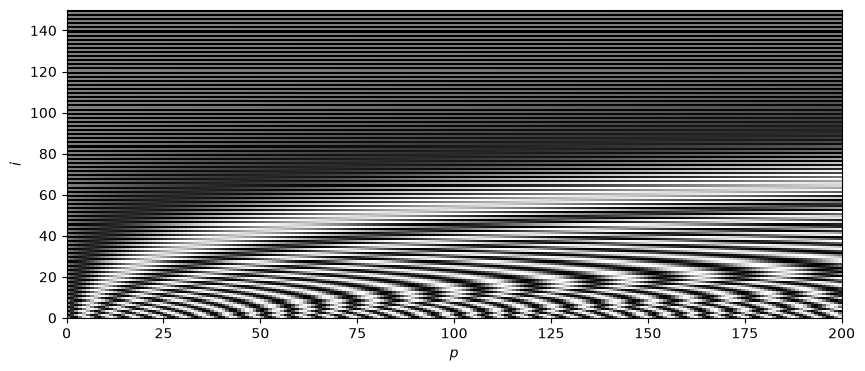

In [54]:
figure_max_length = 200
figure_embed_size = 150
pos_emb = PositionalEncoding(figure_max_length, figure_embed_size)
plt.figure(figsize=(10, 4))
plt.pcolormesh(pos_emb.pos_embeddings[0].numpy().T, vmin=-1, vmax=1, cmap='binary')
plt.xlabel('$p$')
plt.ylabel('$i$')
plt.show()

#### 멀티 헤드 어텐션

In [55]:
def scaled_dot_product_attention(Q, K, V, mask):
    # Q (..., seq_len_query, depth)
    # K (..., seq_len_key, depth)
    # V (..., seq_len_key, value_depth)
    # mask (..., seq_len_query, seq_len_key)

    QK = tf.matmul(Q, K, transpose_b=True) # (..., seq_len_query, seq_len_key)

    depth = tf.cast(tf.shape(K)[-1], tf.float32)
    scaled_attention_logits = QK / tf.math.sqrt(depth)

    if mask is not None:
        scaled_attention_logits += (mask * -1e9)

    attention_weights = tf.nn.softmax(scaled_attention_logits)
    output = tf.matmul(attention_weights, V) # (..., seq_len_query, value_depth)
    
    return output, attention_weights

In [56]:
class MultiHeadAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, **kwargs):
        super().__init__(**kwargs)

        assert d_model % num_heads == 0, 'd_model must be divided by num_heads'
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.depth = d_model // num_heads

        self.linear_Q = tf.keras.layers.Dense(d_model)
        self.linear_K = tf.keras.layers.Dense(d_model)
        self.linear_V = tf.keras.layers.Dense(d_model)
        self.linear_output = tf.keras.layers.Dense(d_model)

    def split_heads(self, x, batch_size):
        # x.shape == (batch_size, seq_len, num_heads, depth)
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        # x.shape == (batch_size, num_heads, seq_len, depth)
        x = tf.transpose(x, (0, 2, 1, 3))
        return x

    def call(self, Q, K, V, mask=None):
        batch_size = tf.shape(Q)[0]
        
        Q = self.linear_Q(Q)  # (batch_size, seq_len, d_model)
        K = self.linear_K(K)  # (batch_size, seq_len, d_model)
        V = self.linear_V(V)  # (batch_size, seq_len, d_model)

        Q = self.split_heads(Q, batch_size)  # (batch_size, num_heads, seq_len, depth)
        K = self.split_heads(K, batch_size)  # (batch_size, num_heads, seq_len, depth)
        V = self.split_heads(V, batch_size)  # (batch_size, num_heads, seq_len, depth)

        # scaled_attention.shape == (batch_size, num_heads, seq_len, depth)
        # attention_weights.shape == (batch_size, num_heads, seq_len, seq_len)
        scaled_attention, attention_weights = scaled_dot_product_attention(Q, K, V, mask)

        # scaled_attention.shape == (batch_size, seq_len, num_heads, depth)
        scaled_attention = tf.transpose(scaled_attention, (0, 2, 1, 3))

        # concat_attention.shape == (batch_size, seq_len, d_model)
        concat_attention = tf.reshape(scaled_attention, (batch_size, -1, self.d_model))

        output = self.linear_output(concat_attention) # (batch_size, seq_len, d_model)
        return output, attention_weights

In [57]:
temp_mha = MultiHeadAttention(d_model=512, num_heads=8)
y = tf.random.uniform((1, 60, 512))  # (batch_size, encoder_seq_len, d_model)
out, attn = temp_mha(y, y, y, mask=None)
out.shape, attn.shape

(TensorShape([1, 60, 512]), TensorShape([1, 8, 60, 60]))

In [58]:
tf.random.set_seed(42)

N = 2
num_heads = 8
dropout_rate = 0.1
n_units = 128

encoder_pad_mask = tf.keras.ops.not_equal(encoder_input_ids, 0)[:, tf.newaxis]
Z = encoder_in
for _ in range(N):
    skip = Z
    attn_layer = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=embed_size, dropout=dropout_rate)
    Z = attn_layer(Z, value=Z, attention_mask=encoder_pad_mask)
    Z = tf.keras.layers.LayerNormalization()(tf.keras.layers.Add()([Z, skip]))
    
    skip = Z
    Z = tf.keras.layers.Dense(n_units, activation='relu')(Z)
    Z = tf.keras.layers.Dense(embed_size)(Z)
    Z = tf.keras.layers.Dropout(dropout_rate)(Z)
    Z = tf.keras.layers.LayerNormalization()(tf.keras.layers.Add()([Z, skip]))

In [59]:
decoder_pad_mask = tf.keras.ops.not_equal(decoder_input_ids, 0)[:, tf.newaxis]
causal_mask = tf.linalg.band_part(
    tf.ones((batch_max_len_dec, batch_max_len_dec)), -1, 0)

In [60]:
encoder_outputs = Z
Z = decoder_in
for _ in range(N):
    skip = Z
    attn_layer = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=embed_size, dropout=dropout_rate)
    Z = attn_layer(Z, value=Z, attention_mask=(causal_mask & decoder_pad_mask))
    Z = tf.keras.layers.LayerNormalization()(tf.keras.layers.Add()([Z, skip]))

    skip = Z
    attn_layer = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=embed_size, dropout=dropout_rate)
    Z = attn_layer(Z, value=encoder_outputs, attention_mask=encoder_pad_mask)
    Z = tf.keras.layers.LayerNormalization()(tf.keras.layers.Add()([Z, skip]))

    skip = Z
    Z = tf.keras.layers.Dense(n_units, activation='relu')(Z)
    Z = tf.keras.layers.Dense(embed_size)(Z)
    Z = tf.keras.layers.LayerNormalization()(tf.keras.layers.Add()([Z, skip]))

In [61]:
Y_proba = tf.keras.layers.Dense(vocab_size, activation='softmax')(Z)
model = tf.keras.models.Model(inputs=[encoder_inputs, decoder_inputs], outputs=[Y_proba])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit((X_train, X_train_dec), Y_train, epochs=10,
                    validation_data=((X_valid, X_valid_dec), Y_valid))

Epoch 1/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1082s 343ms/step - accuracy: 0.9354 - loss: 0.3227 - val_accuracy: 0.9502 - val_loss: 0.2155
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1092s 349ms/step - accuracy: 0.9509 - loss: 0.2084 - val_accuracy: 0.9548 - val_loss: 0.1905
Epoch 3/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1073s 343ms/step - accuracy: 0.9541 - loss: 0.1902 - val_accuracy: 0.9558 - val_loss: 0.1827
Epoch 4/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1049s 336ms/step - accuracy: 0.9562 - loss: 0.1790 - val_accuracy: 0.9579 - val_loss: 0.1736
Epoch 5/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1005s 322ms/step - accuracy: 0.9576 - loss: 0.1711 - val_accuracy: 0.9588 - val_loss: 0.1688
Epoch 6/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1103s 353ms/step - accuracy: 0.9589 - loss: 0.1642 - val_accuracy: 0.9591 - val_loss: 0.1664
Epoch 7/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1032s 330ms/step - accuracy: 0.9597 - loss: 0.1592 - val_accuracy: 0.9605 - val_loss: 0.1623
Epoch 8/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1025s 328ms/s

In [62]:
translate('I like soccer and also going to the beach.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


'me gusta el fútbol y también voy a la playa'

## 16.7 허깅 페이스의 트랜스포머스 라이브러리

In [63]:
from transformers import pipeline

model_name = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
classifier = pipeline('sentiment-analysis', model=model_name)

classifier('The actors were very convincing.')

[{'label': 'POSITIVE', 'score': 0.9998071789741516}]

In [64]:
classifier(['I am from India.', 'I am from Iraq.'])

[{'label': 'POSITIVE', 'score': 0.9896161556243896},
 {'label': 'NEGATIVE', 'score': 0.9811071157455444}]

In [65]:
classifier(['I am from South Korea.', 'I am from North Korea.'])

[{'label': 'POSITIVE', 'score': 0.6141339540481567},
 {'label': 'NEGATIVE', 'score': 0.889072060585022}]

In [66]:
model_name = 'huggingface/distilbert-base-uncased-finetuned-mnli'
classifier_mnli = pipeline('text-classification', model=model_name)

classifier_mnli('She loves me. [SEP] She loves me not.')

[{'label': 'contradiction', 'score': 0.9790192246437073}]

In [67]:
classifier_mnli('I am sick. [SEP] I have a headache.')

[{'label': 'entailment', 'score': 0.8734965324401855}]

## 연습문제

### ⑧

In [68]:
default_reber_grammar = [
    [('B', 1)],
    [('T', 2), ('P', 3)],
    [('S', 2), ('X', 4)],
    [('T', 3), ('V', 5)],
    [('X', 3), ('S', 6)],
    [('P', 4), ('V', 6)],
    [('E', None)]
]

embedded_reber_grammar = [
    [('B', 1)],
    [('T', 2), ('P', 3)],
    [(default_reber_grammar, 4)],
    [(default_reber_grammar, 5)],
    [('T', 6)],
    [('P', 6)],
    [('E', None)]
]

def generate_string(grammar):
    state = 0
    output = []
    while state is not None:
        idx = np.random.randint(len(grammar[state]))
        production, state = grammar[state][idx]
        if isinstance(production, list):
            production = (generate_string(production))
        output.append(production)
    return ''.join(output)


for _ in range(10):
    print(generate_string(embedded_reber_grammar), end=' ')

BPBPVPSEPE BTBTSSXSETE BPBPVVEPE BPBTXXVVEPE BTBPTTVVETE BPBPTTVPXTTTVPSEPE BTBPTVPSETE BTBTSXSETE BTBTSSXXTTTVVETE BPBTXXTVPSEPE 

In [69]:
POSSIBLE_CHARS = 'BEPSTVX'

def generate_corrupted_string(grammar, chars=POSSIBLE_CHARS):
    good_string = generate_string(grammar)
    idx = np.random.randint(len(good_string))
    bad_char = np.random.choice(list(set(chars) - set(good_string[idx])))
    return good_string[:idx] + bad_char + good_string[idx + 1:]


for _ in range(10):
    print(generate_corrupted_string(embedded_reber_grammar), end=' ')

BPBTSPXXVPSEPE BTBTVSETE BPBTXXTTVPBTTVVEPE BTSPTVPSETE BPBVTVPSEPE BPBESXSEPE BPBPVVESE BTBVVVETE PPBTSXXTVPSEPE BPBPVPXTVPXVVTPE 

In [70]:
def string_to_ids(s, chars=POSSIBLE_CHARS):
    return [chars.index(c) for c in s]

example_string = generate_string(embedded_reber_grammar)
print(example_string)
string_to_ids(example_string)

BPBPTVVEPE


[0, 2, 0, 2, 4, 5, 5, 1, 2, 1]

In [71]:
def generate_dataset(size):
    good_strings = [string_to_ids(generate_string(embedded_reber_grammar))
                    for _ in range(size // 2)]
    bad_strings = [string_to_ids(generate_corrupted_string(embedded_reber_grammar))
                   for _ in range(size - size // 2)]
    all_strings = good_strings + bad_strings
    X = tf.ragged.constant(all_strings, ragged_rank=1).to_tensor()
    y = tf.constant([1.] * len(good_strings) + [0.] * len(bad_strings))
    return tf.data.Dataset.from_tensor_slices((X, y))

In [72]:
tf.random.set_seed(42)

train_set = generate_dataset(10000).shuffle(10000).batch(32).prefetch(1)
valid_set = generate_dataset(2000).batch(32).prefetch(1)

In [73]:
for X, y in train_set.take(1):
    print(X[0], y[0])

tf.Tensor(
[3 2 0 4 3 6 6 4 4 4 5 5 1 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0], shape=(38,), dtype=int32) tf.Tensor(0.0, shape=(), dtype=float32)


In [74]:
embed_size = 5
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None,)),
    tf.keras.layers.Embedding(
        input_dim=len(POSSIBLE_CHARS), output_dim=embed_size, mask_zero=True),
    tf.keras.layers.GRU(30),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.02, momentum = 0.95, nesterov=True)
model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])
history = model.fit(train_set, epochs=20, validation_data=valid_set)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5222 - loss: 0.6917 - val_accuracy: 0.6075 - val_loss: 0.6850
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5649 - loss: 0.6711 - val_accuracy: 0.4620 - val_loss: 0.6675
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5619 - loss: 0.6589 - val_accuracy: 0.4620 - val_loss: 0.6574
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5689 - loss: 0.6516 - val_accuracy: 0.6220 - val_loss: 0.6361
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6134 - loss: 0.6259 - val_accuracy: 0.6560 - val_loss: 0.6012
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6810 - loss: 0.5642 - val_accuracy: 0.7920 - val_loss: 0.4617
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8118 - loss: 0.4171 - val_accuracy: 0.8645 - val_loss: 0.3630
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8762 - loss: 0.3102 - val_accuracy: 0.

In [75]:
test_strings = ["BPBTSSSSSSSXXTTVPXVPXTTTTTVVETE",
                "BPBTSSSSSSSXXTTVPXVPXTTTTTVVEPE"]
X_test = tf.constant([string_to_ids(s) for s in test_strings])
y_proba = model.predict(X_test)

for string, proba in zip(test_strings, y_proba):
    print(f'{string}: {proba[0]*100:.2f}%')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
BPBTSSSSSSSXXTTVPXVPXTTTTTVVETE: 35.12%
BPBTSSSSSSSXXTTVPXVPXTTTTTVVEPE: 73.78%


### ⑨

In [76]:
from datetime import date

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

def random_dates(n_dates):
    min_date = date(1000, 1, 1).toordinal()
    max_date = date(9999, 12, 31).toordinal()

    ordinals = np.random.randint(min_date, max_date + 1, size=n_dates)
    dates = [date.fromordinal(ordinal) for ordinal in ordinals]

    x = [MONTHS[dt.month - 1] + ' ' + dt.strftime('%d, %Y') for dt in dates]
    y = [dt.isoformat() for dt in dates]
    return x, y

In [77]:
np.random.seed(42)

print('{:25s}{:25s}'.format('Input', 'Target'))
print('-' * 50)
for x, y in zip(*random_dates(3)):
    print(f'{x:25s}{y:25s}')

Input                    Target                   
--------------------------------------------------
September 20, 7075       7075-09-20               
May 15, 8579             8579-05-15               
January 11, 7103         7103-01-11               


In [78]:
INPUT_CHARS = list(set(''.join(MONTHS) + '0123456789, '))
OUTPUT_CHARS = list('0123456789-')

In [79]:
def date_str_to_ids(date_str, chars):
    return [chars.index(c) for c in date_str]

def preprocessing(date_strs, chars):
    X_ids = [date_str_to_ids(date_str, chars) for date_str in date_strs]
    X = tf.ragged.constant(X_ids, ragged_rank=1)
    return (X + 1).to_tensor()

#### Seq2Seq Model

In [80]:
tf.random.set_seed(42)

def create_dataset(n_dates):
    x, y = random_dates(n_dates)
    X = preprocessing(x, INPUT_CHARS)
    Y = preprocessing(y, OUTPUT_CHARS)
    return tf.data.Dataset.from_tensor_slices((X, Y))

train_set = create_dataset(10000).shuffle(10000).batch(32).prefetch(1)
valid_set = create_dataset(2000).batch(32).prefetch(1)
test_set = create_dataset(2000).batch(32).prefetch(1)

In [81]:
embed_size = 32
max_output_len = 10

encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None,)),
    tf.keras.layers.Embedding(
        input_dim=(len(INPUT_CHARS) + 1), output_dim=embed_size, mask_zero=True),
    tf.keras.layers.GRU(128)
])

decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(max_output_len, 128)),
    tf.keras.layers.GRU(128, return_sequences=True),
    tf.keras.layers.Dense(len(OUTPUT_CHARS) + 1, activation='softmax')
])

model = tf.keras.models.Sequential([
    encoder,
    tf.keras.layers.RepeatVector(max_output_len),
    decoder
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=10, validation_data=valid_set)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.4609 - loss: 1.5035 - val_accuracy: 0.6193 - val_loss: 1.0205
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7219 - loss: 0.7484 - val_accuracy: 0.8016 - val_loss: 0.5346
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8695 - loss: 0.3804 - val_accuracy: 0.9176 - val_loss: 0.2684
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9569 - loss: 0.1738 - val_accuracy: 0.9827 - val_loss: 0.1047
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9931 - loss: 0.0640 - val_accuracy: 0.9967 - val_loss: 0.0421
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9988 - loss: 0.0281 - val_accuracy: 0.9992 - val_loss: 0.0212
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9795 - loss: 0.1107 - val_accuracy: 0.9989 - val_loss: 0.0229
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9998 - loss: 0.0143 - val_accu

In [82]:
model.evaluate(test_set)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 0.0054


[0.005376523360610008, 0.9999499917030334]

In [83]:
X_new = ['September 17, 2009', 'July 14, 1789', 'May 02, 2020']
X_new = preprocessing(X_new, INPUT_CHARS)
for Y_pred in model.predict(X_new):
    print(''.join([OUTPUT_CHARS[c - 1] for c in Y_pred.argmax(axis=1)]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
2009-09-17
1789-07-14
2020-05-02


#### Teacher Forcing Model

In [84]:
tf.random.set_seed(42)

sos_id = len(OUTPUT_CHARS) + 1
def create_dataset(n_dates):
    x, y = random_dates(n_dates)
    X = preprocessing(x, INPUT_CHARS)
    Y = preprocessing(y, OUTPUT_CHARS)

    sos_tokens = tf.fill((tf.shape(Y)[0], 1), sos_id)
    X_dec = tf.concat([sos_tokens, Y[:, :-1]], axis=1)
    
    return tf.data.Dataset.from_tensor_slices(((X, X_dec), Y))

train_set = create_dataset(10000).shuffle(10000).batch(32).prefetch(1)
valid_set = create_dataset(2000).batch(32).prefetch(1)
test_set = create_dataset(2000).batch(32).prefetch(1)

In [85]:
encoder_embed_size = 32
decoder_embed_size = 32
lstm_units = 128

encoder_input = tf.keras.layers.Input(shape=(None,))
encoder_embedding = tf.keras.layers.Embedding(
    input_dim=(len(INPUT_CHARS) + 1), output_dim=encoder_embed_size)(encoder_input)
_, *encoder_state = tf.keras.layers.LSTM(lstm_units, return_state=True)(encoder_embedding)

decoder_input = tf.keras.layers.Input(shape=(None,))
decoder_embedding = tf.keras.layers.Embedding(
    input_dim=(len(OUTPUT_CHARS) + 2), output_dim=decoder_embed_size)(decoder_input)
decoder_lstm_output = tf.keras.layers.LSTM(
    lstm_units, return_sequences=True)(decoder_embedding, initial_state=encoder_state)
decoder_output = tf.keras.layers.Dense(
    len(OUTPUT_CHARS) + 1, activation='softmax')(decoder_lstm_output)

model = tf.keras.models.Model(inputs=[encoder_input, decoder_input], outputs=[decoder_output])
model.compile(loss='sparse_categorical_crossentropy', optimizer='nadam', metrics=['accuracy'])
history = model.fit(train_set, epochs=10, validation_data=valid_set)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.4618 - loss: 1.4720 - val_accuracy: 0.6435 - val_loss: 0.9925
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7576 - loss: 0.6819 - val_accuracy: 0.8666 - val_loss: 0.3985
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9381 - loss: 0.2270 - val_accuracy: 0.9787 - val_loss: 0.1158
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9842 - loss: 0.0916 - val_accuracy: 0.9951 - val_loss: 0.0547
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9984 - loss: 0.0323 - val_accuracy: 0.9991 - val_loss: 0.0226
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9998 - loss: 0.0165 - val_accuracy: 0.9999 - val_loss: 0.0143
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9877 - loss: 0.0645 - val_accuracy: 0.9996 - val_loss: 0.0166
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9999 - loss: 0.0103 - val_accu

In [86]:
model.evaluate(test_set)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9999 - loss: 0.0042


[0.004218118265271187, 0.9999499917030334]